In [36]:
%matplotlib widget
from glob import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import LinearSegmentedColormap
from scipy.spatial.distance import jensenshannon
from sklearn.preprocessing import MinMaxScaler
from umap import UMAP
from IPython.display import display

features = ['src_n_vars', 'src_n_mul', 'src_n_add', 'src_max_const',
            'src_n_xor', 'src_n_terms', 'src_n_or']
names = ['Distinct variables', 'Multiplications', 'Additions', 'Largest constant',
         'XOR operations', 'Expression terms', 'OR operations']
test = pd.read_csv('../../data/predictions_test.csv', usecols=features + ['correct'])
train = pd.read_csv('../../data/predictions_train.csv', usecols=features)
values = test[features].to_numpy()
failed = ~test['correct'].to_numpy()

In [45]:
X = MinMaxScaler().fit_transform(test[features])
xy = UMAP(n_neighbors=100, min_dist=0.5, unique=True, compatibility_layout=True).fit_transform(X)

# Cases with the same seven values share a dot. circles count every case.
points = test.assign(x=xy[:, 0], y=xy[:, 1], failed=failed).groupby(
    features, as_index=False, sort=False
).agg(x=('x', 'first'), y=('y', 'first'), n=('correct', 'size'),
      failure_rate=('failed', 'mean'))

def js_divergence(feature):
    p = test[feature].value_counts(normalize=True)
    q = train[feature].value_counts(normalize=True)
    p, q = p.align(q, join='outer', fill_value=0)
    return 1000 * jensenshannon(p, q, base=2)**2  # millibits

js = np.array([js_divergence(f) for f in features])
print(f'{len(test):,} test cases; {failed.sum():,} failures; {len(points):,} distinct combinations.')

10,885 test cases; 973 failures; 1,502 distinct combinations.


In [38]:
plt.close('UMAP regions')
with plt.ioff():
    fig = plt.figure('UMAP regions', figsize=(12, 7.5))
grid = fig.add_gridspec(7, 3, width_ratios=[1.8, 1.25, 0.30],
                       left=0.05, right=0.95, bottom=0.17, top=0.89,
                       wspace=0.40, hspace=0.75)
ax_map = fig.add_subplot(grid[:5, 0])
colors = ['#4c78a8', '#bd725b']
cmap = LinearSegmentedColormap.from_list('failure', ['#b8bec7', '#bf283a'])
dots = ax_map.scatter(points.x, points.y, s=3 * points.n,
                      c=points.failure_rate, cmap=cmap, vmin=0, vmax=1,
                      edgecolors='none', alpha=0.85)
ax_map.set(xlabel='UMAP 1', ylabel='UMAP 2', aspect='equal')
ax_map.set_title('One dot per seven-value combination; area ∝ cases', fontsize=9)
ax_map.spines[['top', 'right']].set_visible(False)
ax_map.tick_params(labelsize=8)
colorbar = fig.colorbar(dots, ax=ax_map, orientation='horizontal', fraction=0.04, pad=0.15,
                       ticks=[0, 0.5, 1], label='Failure rate within that combination')
colorbar.ax.set_xticklabels(['0%', '50%', '100%'])
span = np.ptp(xy, axis=0).max()
ax_map.set_xlim(xy[:, 0].min() - 0.05 * span, xy[:, 0].max() + 0.05 * span)
ax_map.set_ylim(xy[:, 1].min() - 0.05 * span, xy[:, 1].max() + 0.05 * span)

centers = xy[np.argsort(xy[:, 0])[[len(test) // 4, 3 * len(test) // 4]]]
circles, tags = [], []
for i, color in enumerate(colors):
    radius = np.quantile(np.linalg.norm(xy - centers[i], axis=1), 0.07)
    circle = Circle(centers[i], radius, fill=False, color=color, lw=2, zorder=5)
    ax_map.add_patch(circle)
    circles.append(circle)
    tags.append(ax_map.text(*centers[i], 'AB'[i], color=color, weight='bold',
                            fontsize=13, ha='center', va='center', zorder=6))

profiles = []
for j, name in enumerate(names):
    ax = fig.add_subplot(grid[j, 1])
    lo, hi = values[:, j].min(), values[:, j].max()
    ax.set(xlim=(lo - 0.06 * (hi - lo), hi + 0.06 * (hi - lo)), ylim=(-0.5, 1.5))
    ax.set_yticks([1, 0], ['A', 'B'])
    ax.set_xticks(np.unique(np.linspace(lo, hi, 4).round().astype(int)))
    ax.set_title(name, loc='left', fontsize=9, pad=3)
    ax.tick_params(labelsize=8, length=2)
    ax.spines[['left', 'right', 'top']].set_visible(False)
    ax.spines['bottom'].set_color('0.8')
    row = []
    for i, color in enumerate(colors):
        ax.axhline(1 - i, color='0.9', lw=0.6, zorder=0)
        whisker, = ax.plot([], [], color=color, lw=1)
        bar, = ax.plot([], [], color=color, lw=9, alpha=0.5, solid_capstyle='butt')
        mean, = ax.plot([], [], '|', color=color, ms=14, mew=2)
        row.append((whisker, bar, mean))
    profiles.append(row)
    ax_js = fig.add_subplot(grid[j, 2])
    ax_js.barh(0, js.max() * 1.1, height=0.35, color='0.94')
    ax_js.barh(0, js[j], height=0.35, color='#8973ad')
    ax_js.set(xlim=(0, js.max() * 1.1), ylim=(-0.8, 0.8))
    ax_js.axis('off')
    ax_js.text(1.05, 0.5, f'{js[j]:.3f}', transform=ax_js.transAxes, va='center', fontsize=8)
    if j == 0:
        ax_js.set_title('Train–test JS\n(mbit)', fontsize=9, pad=7)

stats = [fig.text(0.05, y, '', color=color, fontsize=10)
         for y, color in zip([0.28, 0.245], colors)]
overlap = fig.text(0.05, 0.21, '', fontsize=8, color='0.4')
fig.text(0.05, 0.94, 'Drag A/B; scroll to resize', fontsize=10)
fig.text(0.56, 0.96, 'Bar: middle 50% · line: min–max · tick: mean', fontsize=9)
fig.canvas.header_visible = False
fig.canvas.footer_visible = False
fig.canvas.capture_scroll = True

In [39]:
def update():
    global selected
    selected = [np.sum((xy - c.center)**2, axis=1) <= c.radius**2 for c in circles]
    for i, mask in enumerate(selected):
        n = mask.sum()
        text = f"{'AB'[i]}: {n:,} cases"
        stats[i].set_text(text + (f' · {failed[mask].sum():,} failures ({failed[mask].mean():.1%})'
                                  if n else ' · failure rate unavailable'))
        limits = np.quantile(values[mask], [0, 0.25, 0.75, 1], axis=0) if n else np.full((4, 7), np.nan)
        means = values[mask].mean(axis=0) if n else np.full(7, np.nan)
        for j in range(7):
            lo, q1, q3, hi = limits[:, j]
            whisker, bar, mean = profiles[j][i]
            whisker.set_data([lo, hi], [1 - i, 1 - i])
            bar.set_data([q1, q3], [1 - i, 1 - i])
            mean.set_data([means[j]], [1 - i])
        tags[i].set_position(circles[i].center)
    overlap.set_text(f'{(selected[0] & selected[1]).sum():,} cases belong to both circles.')
    fig.canvas.draw_idle()

In [40]:
drag = {'index': None, 'offset': np.zeros(2)}

def nearest(event):
    point = np.array([event.xdata, event.ydata])
    distances = np.array([np.linalg.norm(point - c.center) for c in circles])
    inside = distances <= [c.radius for c in circles]
    return int(np.argmin(np.where(inside, distances, np.inf)) if inside.any() else distances.argmin())

def on_press(event):
    if event.inaxes != ax_map or event.button != 1 or fig.canvas.toolbar.mode:
        return
    i = nearest(event)
    point = np.array([event.xdata, event.ydata])
    inside = np.linalg.norm(point - circles[i].center) <= circles[i].radius
    drag['index'] = i
    drag['offset'] = np.asarray(circles[i].center) - point if inside else np.zeros(2)
    on_motion(event)

def on_motion(event):
    if drag['index'] is not None and event.inaxes == ax_map:
        circles[drag['index']].center = np.array([event.xdata, event.ydata]) + drag['offset']
        update()

def on_release(event):
    drag['index'] = None

def on_scroll(event):
    if event.inaxes == ax_map and not fig.canvas.toolbar.mode:
        circle = circles[nearest(event)]
        circle.set_radius(np.clip(circle.radius * 1.12**event.step, 0.002 * span, 0.75 * span))
        update()

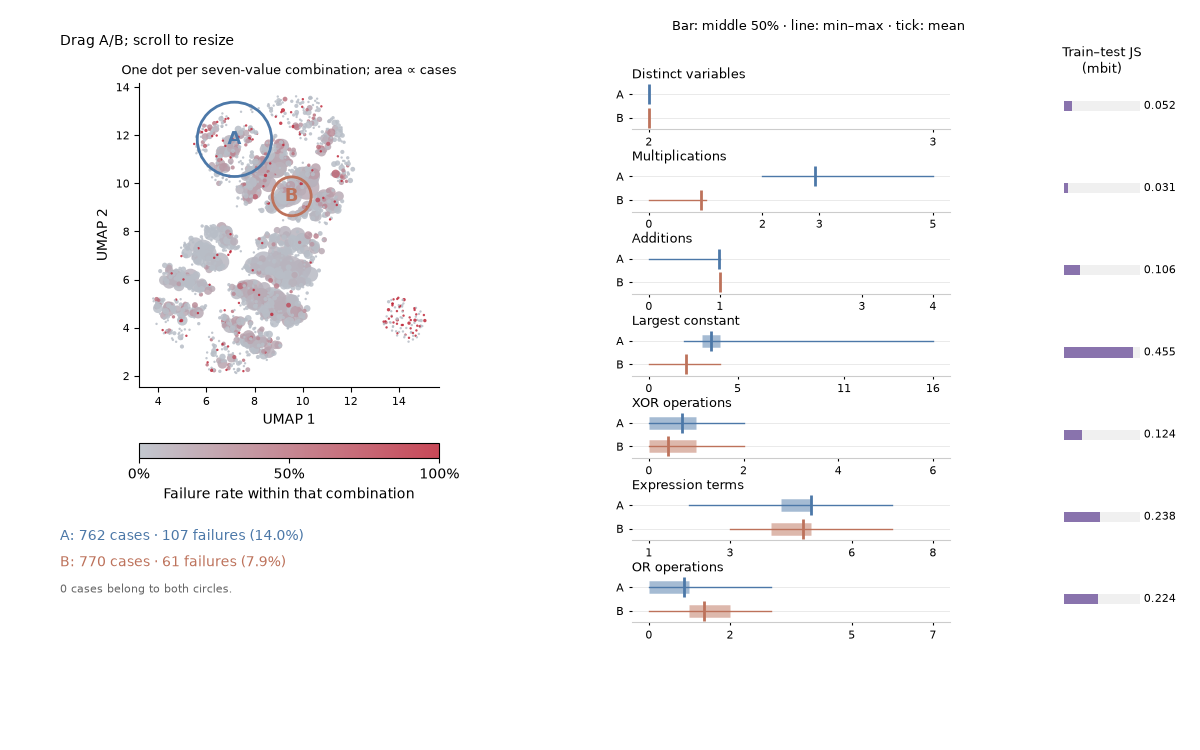

In [41]:
for event, callback in [('button_press_event', on_press), ('motion_notify_event', on_motion),
                        ('button_release_event', on_release), ('scroll_event', on_scroll),
                        ('figure_leave_event', on_release)]:
    fig.canvas.mpl_connect(event, callback)
update()
display(fig.canvas)

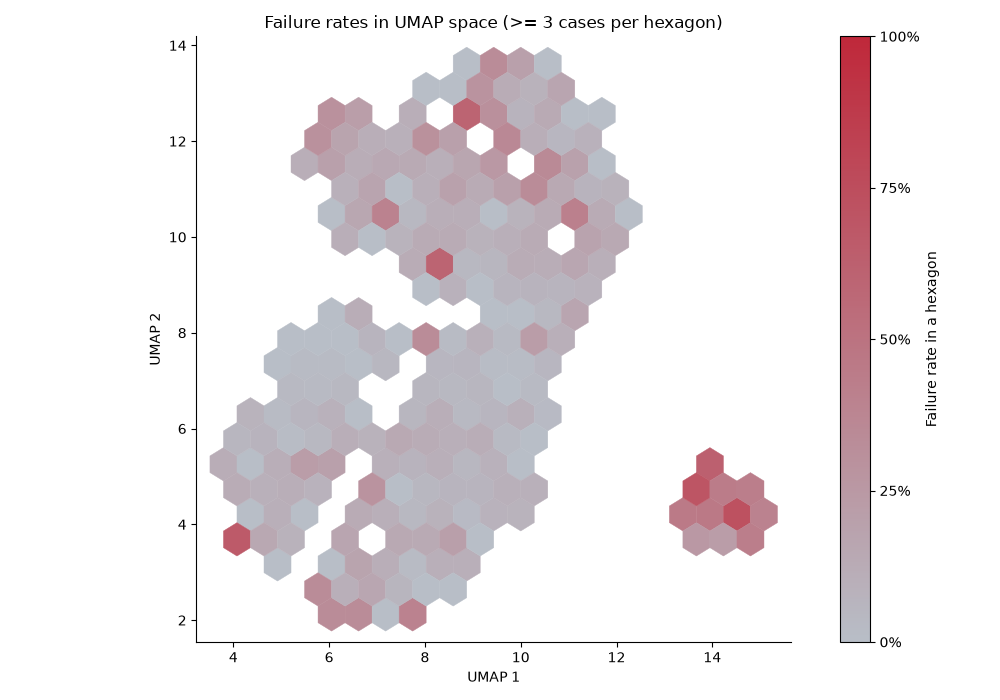

In [44]:
cmap_failure = LinearSegmentedColormap.from_list("failure_rate",["#b8bec7","#bf283a"])
fig, ax = plt.subplots(figsize=(10, 7))

hb = ax.hexbin(xy[:,0], xy[:, 1], C=failed, reduce_C_function=np.mean, gridsize=20, mincnt=3, cmap=cmap_failure, vmin=0, vmax=1, linewidths=0.3)

ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("Failure rates in UMAP space (>= 3 cases per hexagon)")
ax.set_aspect("equal")
ax.spines[["top", "right"]].set_visible(False)

colorbar = fig.colorbar(hb, ax=ax, label="Failure rate in a hexagon")

colorbar.set_ticks([0, 0.25, 0.5, 0.75, 1])
colorbar.set_ticklabels(["0%", "25%", "50%", "75%", "100%"])

plt.tight_layout()
plt.show()